# Iris Species Classification
**Goal:** predict the iris species from four flower measurements, comparing **Logistic Regression**, **Random Forest** and **KNN**.

Put `Iris.csv` in the same folder as this notebook, then run all cells top to bottom.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

SEED = 42

## Step 1: Load, explore and preprocess

In [5]:
df = pd.read_csv("Iris.csv")
print("Shape:", df.shape)
df.head()

Shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows (ignoring Id):", df.drop(columns="Id").duplicated().sum())
print("\nClass balance:")
print(df["Species"].value_counts())

Missing values per column:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicate rows (ignoring Id): 3

Class balance:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


**Preprocessing decisions**
- **No missing values**, so no imputation is needed.
- **Drop `Id`:** it is only a row counter and carries no signal.
- **Encode `Species`:** scikit-learn needs a numeric target, so the labels become 0/1/2.
- **Keep the 3 duplicate rows:** they are genuine measurements and 3 rows is negligible.
- **Stratified 80/20 split:** each species keeps the same share (10 of each) in the test set.
- **Scaling** (done later, inside pipelines): Logistic Regression and KNN are sensitive to feature scale; Random Forest is not.

In [7]:
df = df.drop(columns="Id")

le = LabelEncoder()
df["Species_enc"] = le.fit_transform(df["Species"])
print("Encoding:", {c: int(i) for i, c in enumerate(le.classes_)})

X = df.drop(columns=["Species", "Species_enc"])
y = df["Species_enc"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Encoding: {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}
Train: (120, 4)  Test: (30, 4)


## Step 2: Feature engineering (which features matter?)

Correlation with the target:
PetalWidthCm     0.956
PetalLengthCm    0.949
SepalLengthCm    0.783
SepalWidthCm    -0.419
Name: Species_enc, dtype: float64


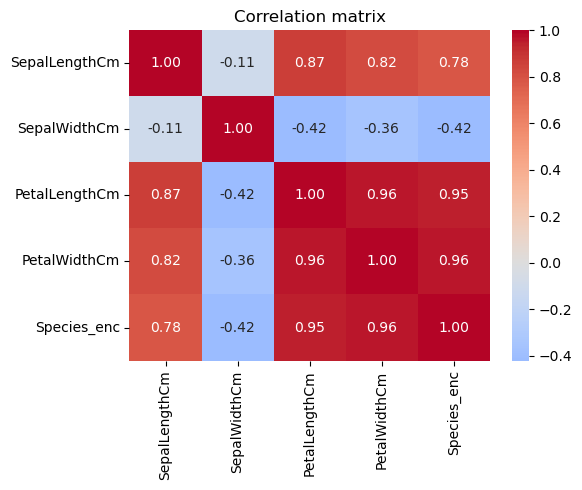

In [8]:
corr = df.drop(columns="Species").corr()
print("Correlation with the target:")
print(corr["Species_enc"].drop("Species_enc").sort_values(ascending=False).round(3))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

PetalLengthCm    0.450
PetalWidthCm     0.410
SepalLengthCm    0.121
SepalWidthCm     0.019
dtype: float64


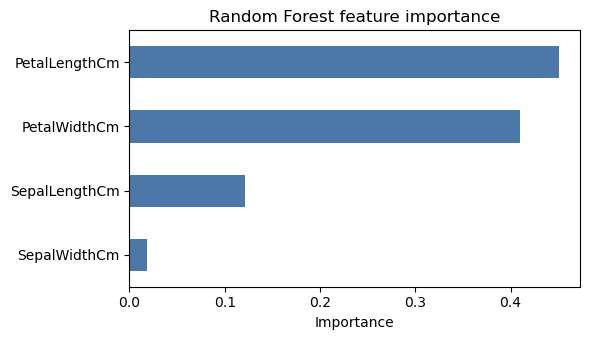

In [9]:
rf_fi = RandomForestClassifier(n_estimators=300, random_state=SEED).fit(X_train, y_train)
imp = pd.Series(rf_fi.feature_importances_, index=X.columns).sort_values()
print(imp.sort_values(ascending=False).round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
imp.plot.barh(ax=ax, color="#4C78A8")
ax.set_title("Random Forest feature importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

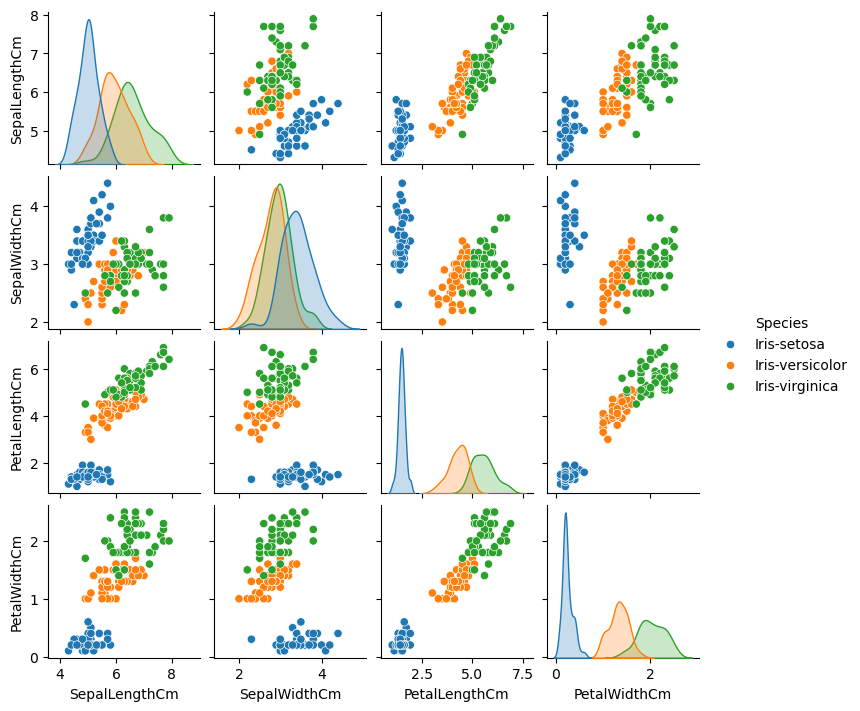

In [10]:
sns.pairplot(df.drop(columns="Species_enc"), hue="Species", height=1.8)
plt.show()

**Findings:** the two petal features dominate (correlation about 0.95, importance about 0.85 combined). `SepalWidthCm` is the weakest feature (importance about 0.02). I keep all four features because the dataset is tiny and the weak feature does no harm; `SepalWidthCm` is the one to drop if you want a leaner model.

## Step 3: Train three models

In [11]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print("trained:", name)

trained: Logistic Regression
trained: Random Forest
trained: KNN (k=5)


## Step 4: Evaluate and compare
Precision, recall and F1 are **macro-averaged** over the three species. I also report 5-fold cross-validated accuracy on all 150 rows, because a 30-row test set moves in steps of 3.3% per flower.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows, preds = [], {}
for name, m in models.items():
    p = m.predict(X_test)
    preds[name] = p
    cvs = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision (macro)": precision_score(y_test, p, average="macro"),
        "Recall (macro)": recall_score(y_test, p, average="macro"),
        "F1 (macro)": f1_score(y_test, p, average="macro"),
        "5-fold CV acc (mean)": cvs.mean(),
        "CV std": cvs.std(),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision (macro),Recall (macro),F1 (macro),5-fold CV acc (mean),CV std
Model,,,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9533,0.0452
Random Forest,0.9000,0.9024,0.9000,0.8997,0.9600,0.0389
KNN (k=5),0.9333,0.9444,0.9333,0.9327,0.9733,0.0249


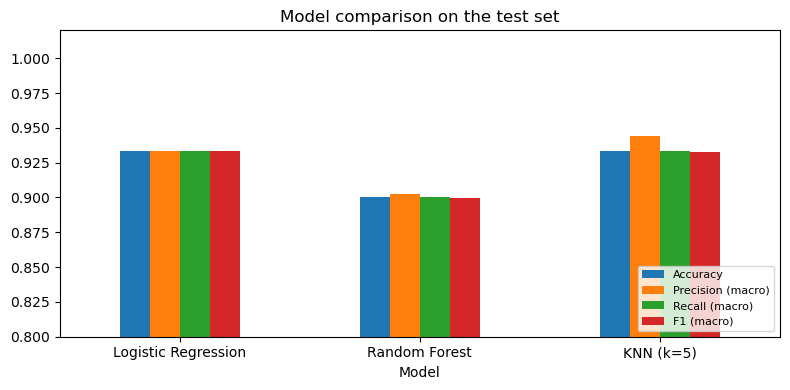

In [13]:
results[["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]].plot.bar(figsize=(8, 4), rot=0)
plt.ylim(0.8, 1.02)
plt.title("Model comparison on the test set")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## Step 5: Best model analysis and conclusion
A 30-row test set ties easily, so I select on 5-fold CV accuracy (all 150 rows) and use test F1 only as a tie-break.

In [14]:
best = results.sort_values(["5-fold CV acc (mean)", "F1 (macro)"], ascending=False).index[0]
print("Best model:", best)
print()
print(classification_report(y_test, preds[best], target_names=le.classes_))

Best model: KNN (k=5)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



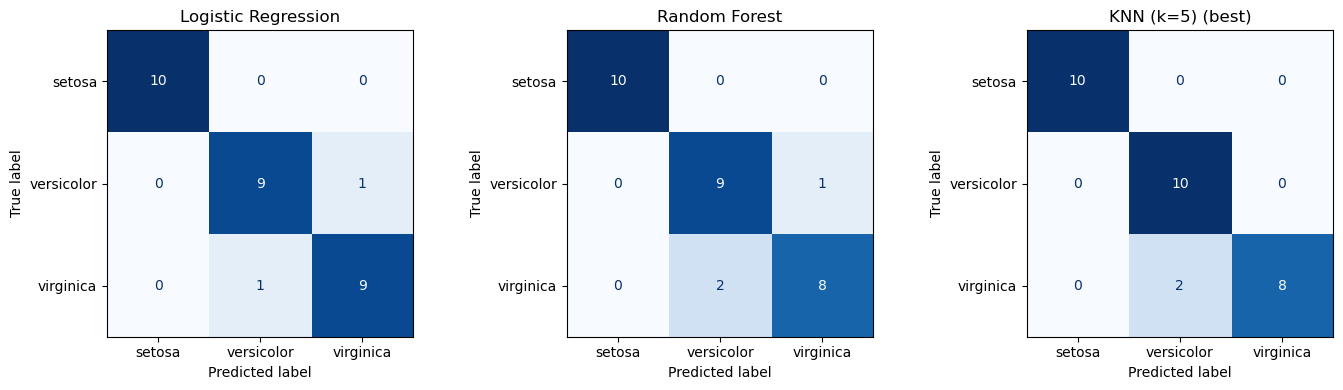

In [15]:
labels = [c.replace("Iris-", "") for c in le.classes_]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=labels).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name + (" (best)" if name == best else ""))
plt.tight_layout()
plt.show()

### Conclusion
1. **KNN (k=5)** is the best model: 93.3% test accuracy and the highest cross-validated accuracy (97.3%, lowest variance).
2. Logistic Regression tied it on test accuracy and Random Forest trailed by one flower; with only 30 test rows the test set cannot separate them, which is why selection uses cross-validation.
3. KNN likely wins because the species form compact clusters in petal-size space, which distance-based methods handle well once features are scaled.
4. Every error is on the versicolor/virginica boundary, where those two species overlap; setosa is trivially separable.
5. Iris is an easy dataset, so all three models are effectively equivalent here; with real data I would use more samples or repeated CV before declaring a winner.